In [7]:
!pip install corner 

1) Read in `solutions/transient.npy`. This is a (100 x 3) numpy array, containing some time-series measurements from a transient phenomenon. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

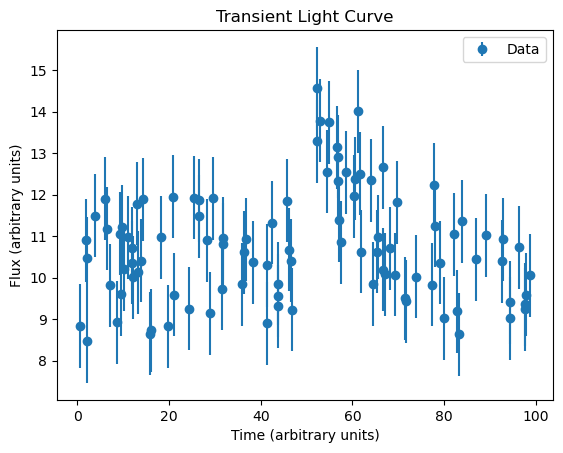

In [11]:
import numpy as np 
import matplotlib.pyplot as plt 


data = np.load('C:/Users/user/Desktop/astrostatistics_bicocca_2026/solutions/transient.npy')
t , flux, unc = data[:,0], data[:,1], data[:,2]

plt.errorbar(t, flux, yerr=unc, fmt='o', label='Data')
plt.xlabel("Time (arbitrary units)")
plt.ylabel("Flux (arbitrary units)")
plt.title("Transient Light Curve")
plt.legend()
plt.show()

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC sampler that we looked at in class (`emcee`, `pymc`), perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$ (careful: uniform in $\ln\alpha$, not $\alpha$).

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) For each parameter, find the median and 90% credible region of the marginalized distribution and quote results as, for instance, $t_0=X^{+Y}_{-Z}$

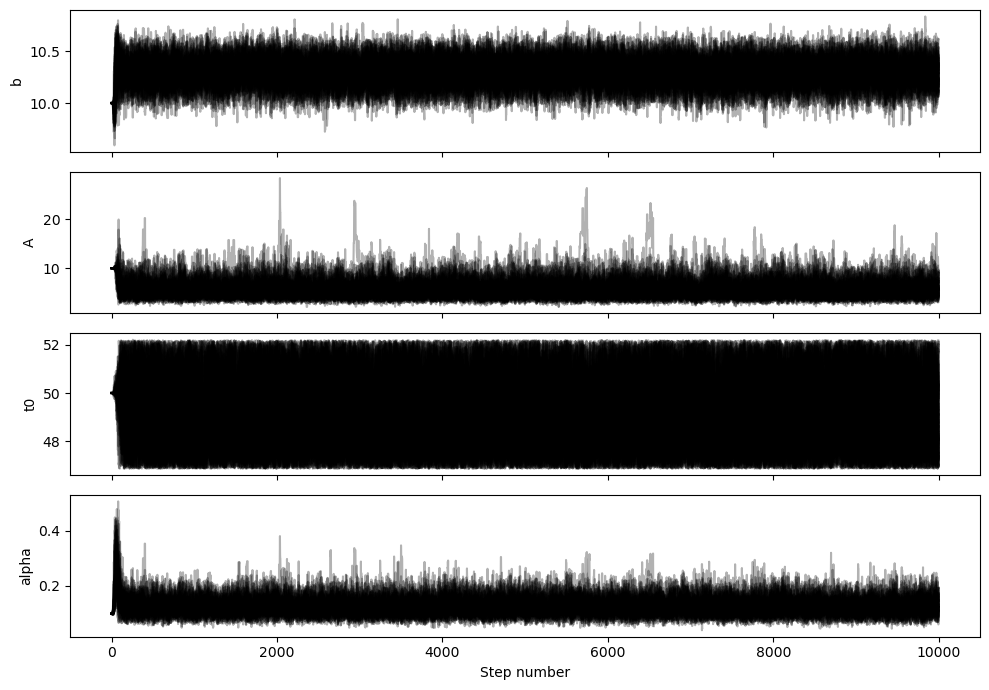

Autocorrelation time per parametro: [52.7259112  73.05687064 74.50690571 62.37461417]
Numero di campioni indipendenti: (6600, 4)


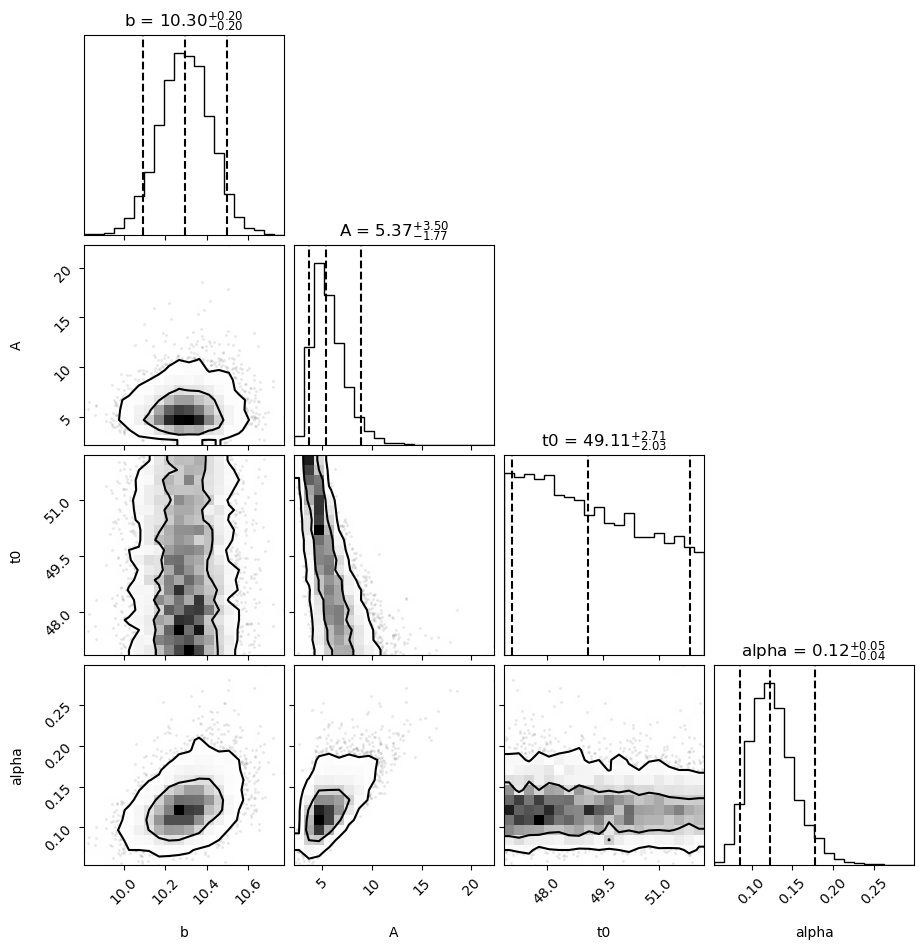

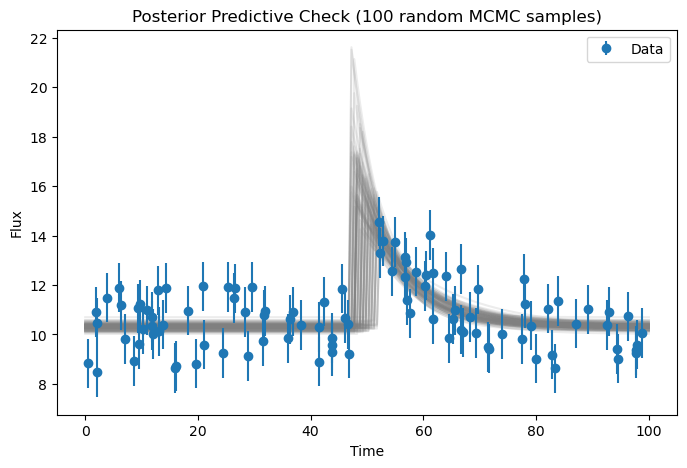

b = 10.297 +0.201 -0.204  (90% CI: [10.092, 10.497])
A = 5.373 +3.503 -1.774  (90% CI: [3.599, 8.876])
t0 = 49.109 +2.713 -2.030  (90% CI: [47.079, 51.822])
alpha = 0.123 +0.055 -0.037  (90% CI: [0.085, 0.177])


In [13]:
import emcee
import corner 

# model

def burst_model(t, b, A, t0, alpha):
    return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0))) #use np.where bc without i first compute np.exp on the all array even for t < t0

# likelihood function

def log_likelihood(theta, x, y, yerr):
    b, A, t0, alpha = theta
    model = burst_model(x, b, A, t0, alpha)
    return -0.5 * np.sum(((y - model) / yerr) ** 2)

# prior function

alphamin, alphamax = np.exp(-5), np.exp(5)

def log_prior(theta):
    b, A, t0, alpha = theta
    if 0 < b < 50 and 0 < A < 50 and 0 < t0 < 100 and alphamin < alpha < alphamax:
        return -np.log(alpha)
    return -np.inf

# posterior function

def log_posterior(theta, x, y, yerr):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr)


initial_guess = [10, 10, 50, 0.1]
n_samples = 10000
n_walkers = 50
n_dim = 4
pos = initial_guess + 1e-4 * np.random.randn(n_walkers, n_dim)

#emcee sampler

sampler = emcee.EnsembleSampler(n_walkers, n_dim, log_posterior, args=(t, flux, unc))

sampler.run_mcmc(pos, n_samples)

# 1. Trace plots delle catene per ispezionare il burn-in
labels = ["b", "A", "t0", "alpha"]
samples = sampler.get_chain()  # shape: (n_samples, n_walkers, n_dim)

fig, axes = plt.subplots(n_dim, figsize=(10, 7), sharex=True)
for i in range(n_dim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("Step number")
plt.tight_layout()
plt.show()

# 2. Calcolo del tempo di autocorrelazione e thinning
tau = sampler.get_autocorr_time()
print("Autocorrelation time per parametro:", tau)

burnin = 3 * int(np.max(tau))   # oppure 1000, basta che sia >= 3*max(tau)
thin = int(np.max(tau))         # prendiamo 1 campione indipendente ogni tau passi

posterior_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)
print("Numero di campioni indipendenti:", posterior_samples.shape)

#corner plot

corner.corner(
    posterior_samples,
    labels=["b", "A", "t0", "alpha"],
    levels=[0.68, 0.95],
    quantiles=[0.05, 0.5, 0.95],
    show_titles=True
)
plt.show()


tgrid = np.linspace(0, 100, 200)
idx = np.random.choice(len(posterior_samples), size=100, replace=False)
chosen_samples = posterior_samples[idx]

plt.figure(figsize=(8, 5))
for theta_sample in chosen_samples:
    plt.plot(tgrid, burst_model(tgrid, *theta_sample), color="gray", alpha=0.15)

plt.errorbar(t, flux, yerr=unc, fmt="o", label="Data")
plt.xlabel("Time")
plt.ylabel("Flux")
plt.title("Posterior Predictive Check (100 random MCMC samples)")
plt.legend()
plt.show()

#median and 90% credible region

labels = ["b", "A", "t0", "alpha"]

for i, label in enumerate(labels):
    low, med, up = np.percentile(posterior_samples[:, i], [5, 50, 95])
    plus = up - med
    minus = med - low
    print(f"{label} = {med:.3f} +{plus:.3f} -{minus:.3f}  (90% CI: [{low:.3f}, {up:.3f}])")